# 16 · Can physiological representations and rebalancing improve binary PSS discrimination?

Exploratory development-only logistic experiment. This teaching notebook displays completed immutable aggregate results, not participant rows. The final test remains sealed.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'config/binary_improvement.json').exists())
report=root/'reports/binary_improvement'
public=report/'911ce0ce6a7b6943'
def table(name):
    value=json.loads((public/(name+'.json')).read_text())
    display(pd.DataFrame([value] if isinstance(value,dict) else value))
def figure(name): display(Image(filename=str(public/'figures'/(name+'.png'))))

## Targets and support

Items4,2,3 give11:4+(6−2)+(6−3). Binary A is≥5; Binary B is≥10. All three valid items are required.

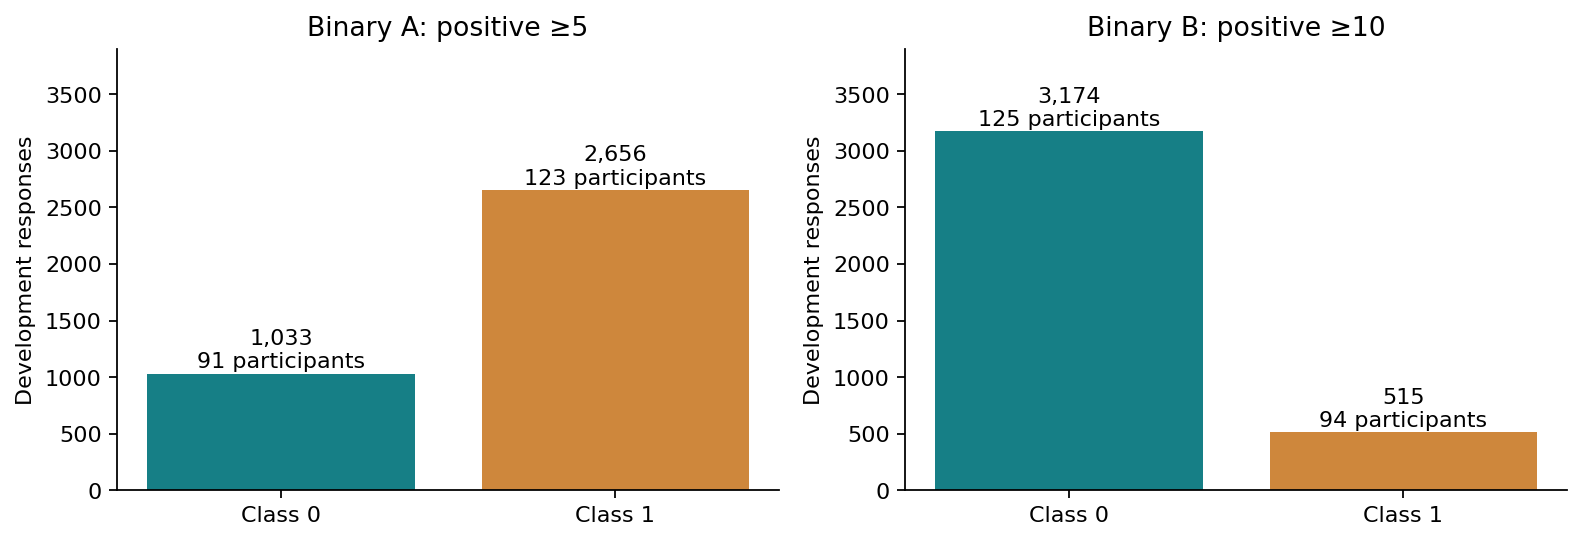

,class0,class0_participants,class1,class1_participants,cohort,fold,model,participants,responses,role,task
110,799,72,2149,98,all,0,context,100,2948,train,A
111,234,19,507,25,all,0,context,25,741,validation,A
112,829,73,2096,99,all,1,context,100,2925,train,A
113,204,18,560,24,all,1,context,25,764,validation,A
114,894,75,2051,98,all,2,context,100,2945,train,A
115,139,16,605,25,all,2,context,25,744,validation,A
116,805,73,2157,98,all,3,context,100,2962,train,A
117,228,18,499,25,all,3,context,25,727,validation,A
118,805,71,2171,99,all,4,context,100,2976,train,A
119,228,20,485,24,all,4,context,25,713,validation,A


In [2]:
figure("01_classes")
support=pd.DataFrame(json.loads((public/"fold_support.json").read_text()))
display(support[support.model.eq("context")])

## Audit and synthetic timing

Synthetic minute start09:22 → cutoff09:21. Six hours=[03:21,09:21). Original fields and offsets are preserved. An export timestamp before the cutoff does not prove live acquisition availability.

In [3]:
display(Markdown((report/"audit.md").read_text()))

# Pre-fit measurement and implementation audit

The audit reuses development-only immutable inputs. No raw sensor processing, final-test exploration,
clock shift, new HRV, or scientific threshold repair was performed. No genuine implementation bug
was identified in the audited scoring, corrected boundaries, or representative saved-feature traces.
`audit/checks.json` records the executed counts; the full test suite covers additional synthetic cases.

| Area | Confirmed implementation | Potential problem or unresolved assumption |
| --- | --- | --- |
| Outcome | All 3,706 scores independently replayed from original normalized item strings; three complete 1–5 integers required, cope/control reversed; ≥5 and ≥10 unchanged | Three-item study composite, not a diagnostic scale; incomplete outcomes excluded without imputation |
| Identity and folds | Stable EMA-key one-to-one matching, participant/fold equality, development-only loader and frozen assignments | Original crosswalk evidence cannot independently establish identity in keyless source CSVs |
| Clock | Independent Python datetime replay of actual local start minus row offset; minute precision subtracts60s, seconds do not | Actual-start application event and acquisition versus receipt/batching remain undocumented |
| Boundaries | Independent datetime checks of all five requested saved lookbacks; left inclusive/right exclusive; deterministic nine-EMA traces into accepted HR source rows | Export time preceding cutoff does not prove a reading was physically acquired or available before the EMA |
| HR | Existing provisional30–240bpm acceptance; rejected clocks/conflicts excluded; identical timestamp/value groups count once; values at different timestamps preserved | Sensor quality and timing accuracy remain unverified; acceptance is not validated physiology |
| Activity | Only supported nonnegative counter pairs wholly contained in windows; resets, source/day/offset changes and long gaps break support; no missing→zero | Counter semantics and sampling remain provisional; no causal activity adjustment |
| Statistics | Minimum2readings/span1s for most moments; slope≥3/span60s; observed UTC-minute means leave empty bins missing; original pair barriers preserved | Sparse bursts can dominate reading-weighted summaries; two points are not representative coverage |
| Model preprocessing | Imputation/scaling/encoding/selection inside each training split; no outcomes, IDs or post-cutoff clocks in predictors | Median filling and missingness flags may encode recording behavior rather than physiology |
| Repeated responses | Original participant outer folds and grouped inner folds; no cross-fold participant donors | Overlapping windows and repeated responses are not independent observations; cluster intervals remain conditional |
| Morning recall | Since waking; supplied current-response wake answer supports a retrospective candidate only | Same-day and unchanged-offset interpretation remain assumptions; do not infer wake from Garmin |
| Midday/Endday recall | Both say since the last prompt, not since the last completed EMA or the whole day | Complete delivered/expired/unanswered prompt history absent; aligned prospective windows cannot be constructed |
| SMOTE | Numeric-only low-dimensional standard interpolation; separate constrained within-person/context variant; every donor remains inside training | Cross-person interpolation and imputed coordinates may be implausible; convex bounds do not establish physiological realism |

Evidence: `src/garmin_ema_baseline/linkage.py`, `src/garmin_preprocessing/normalize.py`,
`src/garmin_hr_activity/features.py`, `src/garmin_comprehensive/features.py`,
`src/garmin_comprehensive/augment.py`, and the exact formulas in
`reports/comprehensive_features/feature_dictionary.md`. Questionnaire code/label evidence is
`reports/ema_baseline/d933d3999d949477/questionnaire_evidence.json`; exact recall wording with local
PDF page citations is `reports/recall_alignment/84f2ff949f1ca478/questionnaire_evidence.md`.
`reports/window_supersession.json` and current-bundle guards reject the earlier int16-overflow versions.
`reports/measurement_evidence_review/8dcdae2b91ab162e/review.md` explains the still-missing exporter evidence.

Synthetic trace: items nervous4, cope2, control3 give11 (positive for both tasks). Local09:22 at
offset−240min gives UTC13:22; minute precision gives cutoff13:21. Six-hour support is
[07:21,13:21). A reading at13:21 is excluded. HR60,60,60 during one observed minute and120 in another
gives reading mean75 but observed-minute mean90. Neither fills unobserved minutes. Counter10→2 is
a reset, never−8steps. These cases are independently covered by the reused/new tests.


## Matched longer-window comparisons

Single-window blocks exclude reference histories and adjacent windows. Nested tuning sees only training participants.

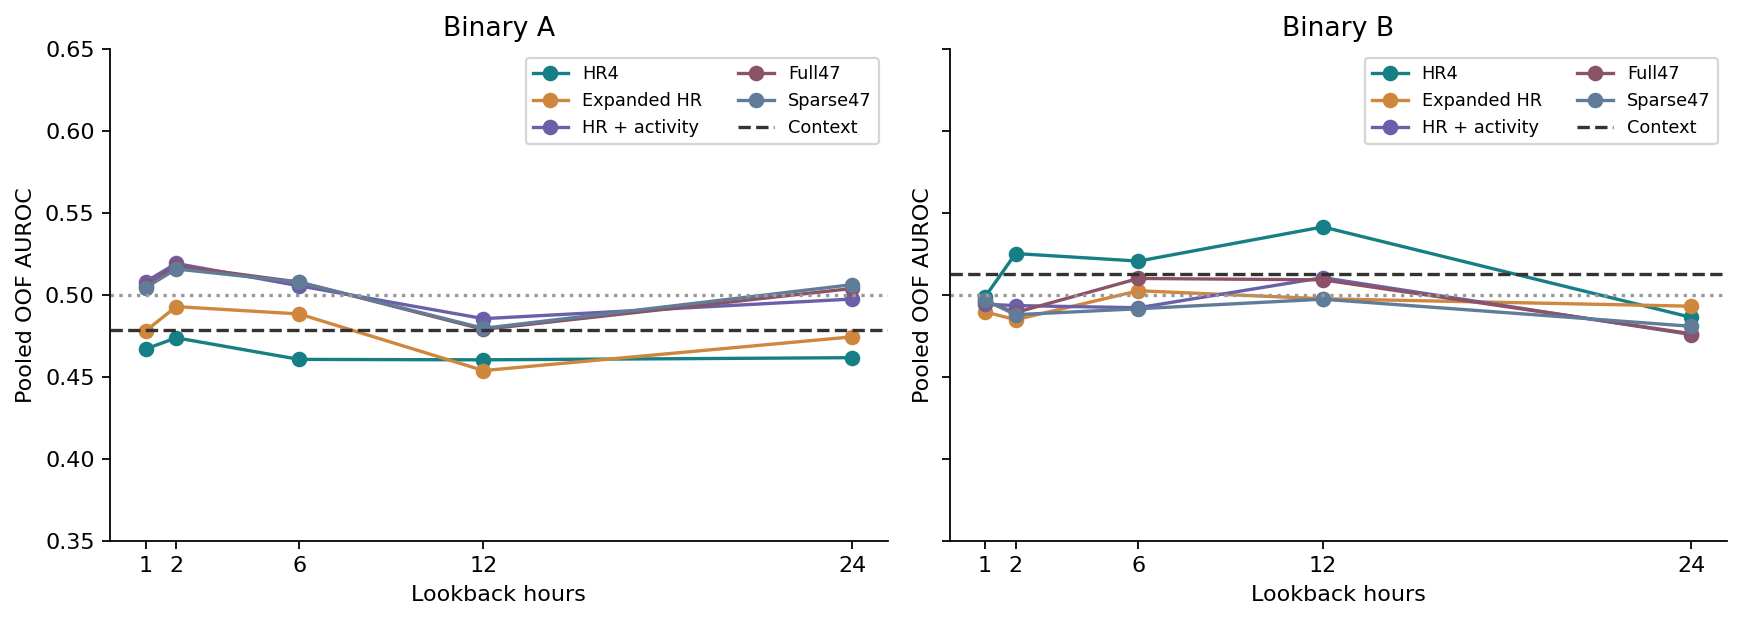

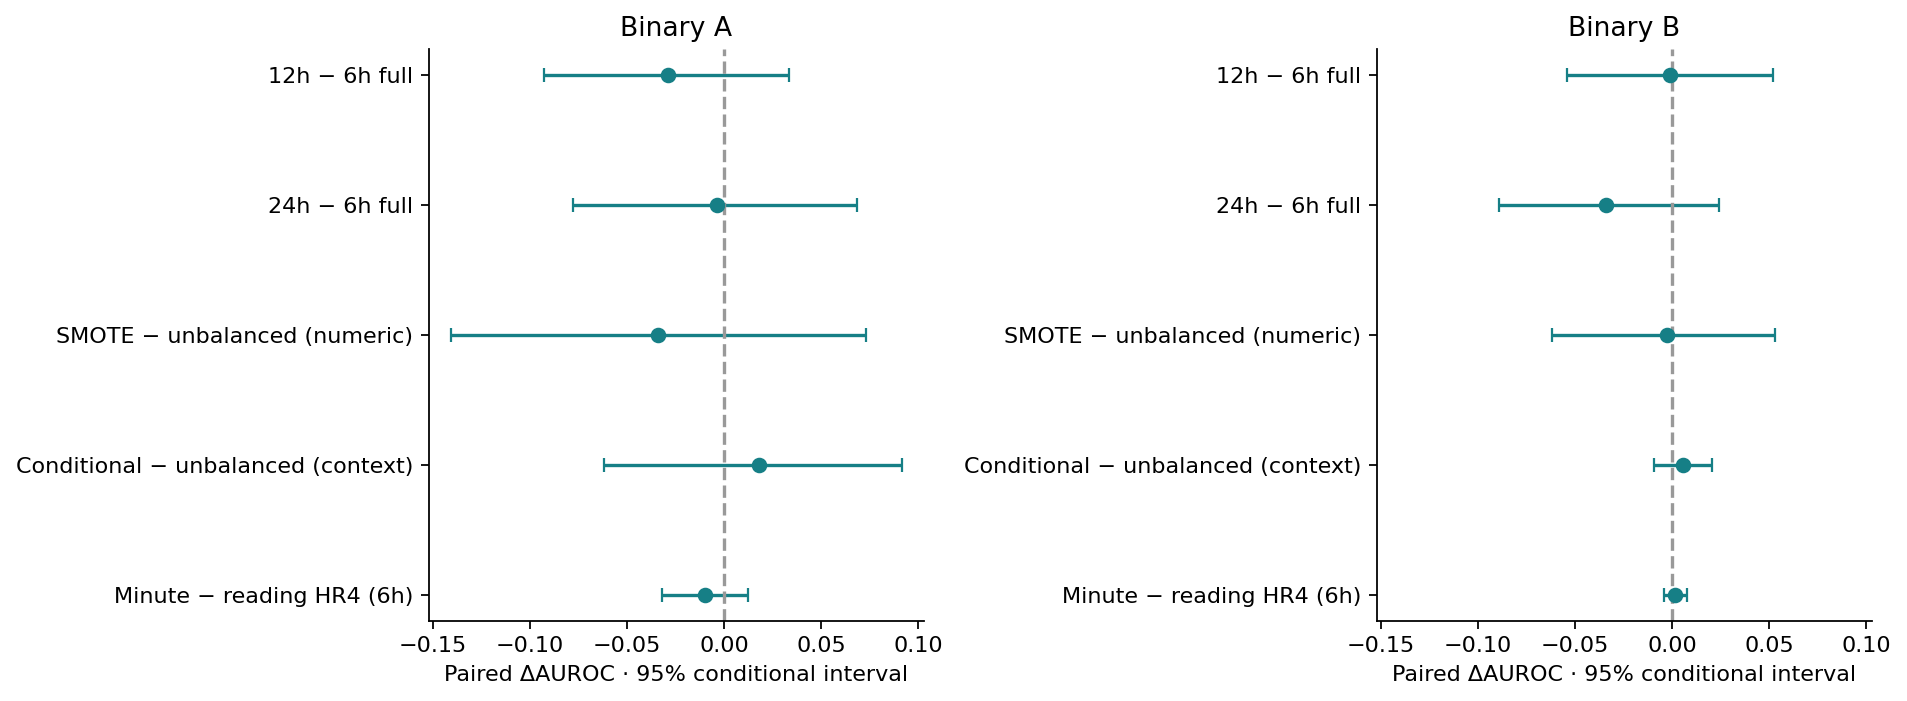

,accuracy,ap,ap_high,ap_low,ap_valid_draws,auroc,auroc_high,auroc_low,auroc_valid_draws,balanced_accuracy,...,precision,predicted_positive,prevalence,probability_sd,responses,sensitivity,specificity,task,tn,tp
0,0.715912,0.735398,0.788805,0.682209,2000,0.519208,0.562402,0.476679,2000,0.498064,...,0.719193,3668,0.719978,0.065630,3689,0.993223,0.002904,A,3,2638
1,0.719978,0.730607,0.789875,0.673233,2000,0.497476,0.549077,0.448059,2000,0.500000,...,0.719978,3689,0.719978,0.042676,3689,1.000000,0.000000,A,0,2656
2,0.716183,0.726138,0.786802,0.667535,2000,0.505551,0.555642,0.458593,2000,0.497956,...,0.719150,3671,0.719978,0.054260,3689,0.993976,0.001936,A,2,2640
3,0.717810,0.722526,0.780758,0.665926,2000,0.508013,0.555608,0.460525,2000,0.500269,...,0.720087,3669,0.719978,0.059480,3689,0.994729,0.005808,A,6,2642
4,0.713744,0.717147,0.779612,0.657022,2000,0.485502,0.525444,0.445709,2000,0.496853,...,0.718699,3658,0.719978,0.060707,3689,0.989834,0.003872,A,4,2629
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,0.884868,0.129869,0.200978,0.078532,2000,0.494716,0.602698,0.371554,2000,0.500000,...,0.000000,0,0.115132,0.129987,608,0.000000,1.000000,B,538,0
140,0.884868,0.097157,0.149092,0.065027,2000,0.406917,0.522048,0.299788,2000,0.500000,...,0.000000,0,0.115132,0.006388,608,0.000000,1.000000,B,538,0
141,0.884868,0.094666,0.144022,0.063895,2000,0.389790,0.499322,0.286103,2000,0.500000,...,0.000000,0,0.115132,0.010618,608,0.000000,1.000000,B,538,0
142,0.884868,0.115132,0.155041,0.080574,2000,0.500000,0.500000,0.500000,2000,0.500000,...,0.000000,0,0.115132,0.000000,608,0.000000,1.000000,B,538,0


In [4]:
figure("02_windows")
figure("03_primary")
table("metrics")

## SMOTE and simpler balancing

Synthetic numeric vector [60,5] and minority neighbor [80,9], interpolation fraction 0.25, produce [65,6]. These are augmented feature summaries, never new sensor readings. Context categories and missingness flags are not interpolated.

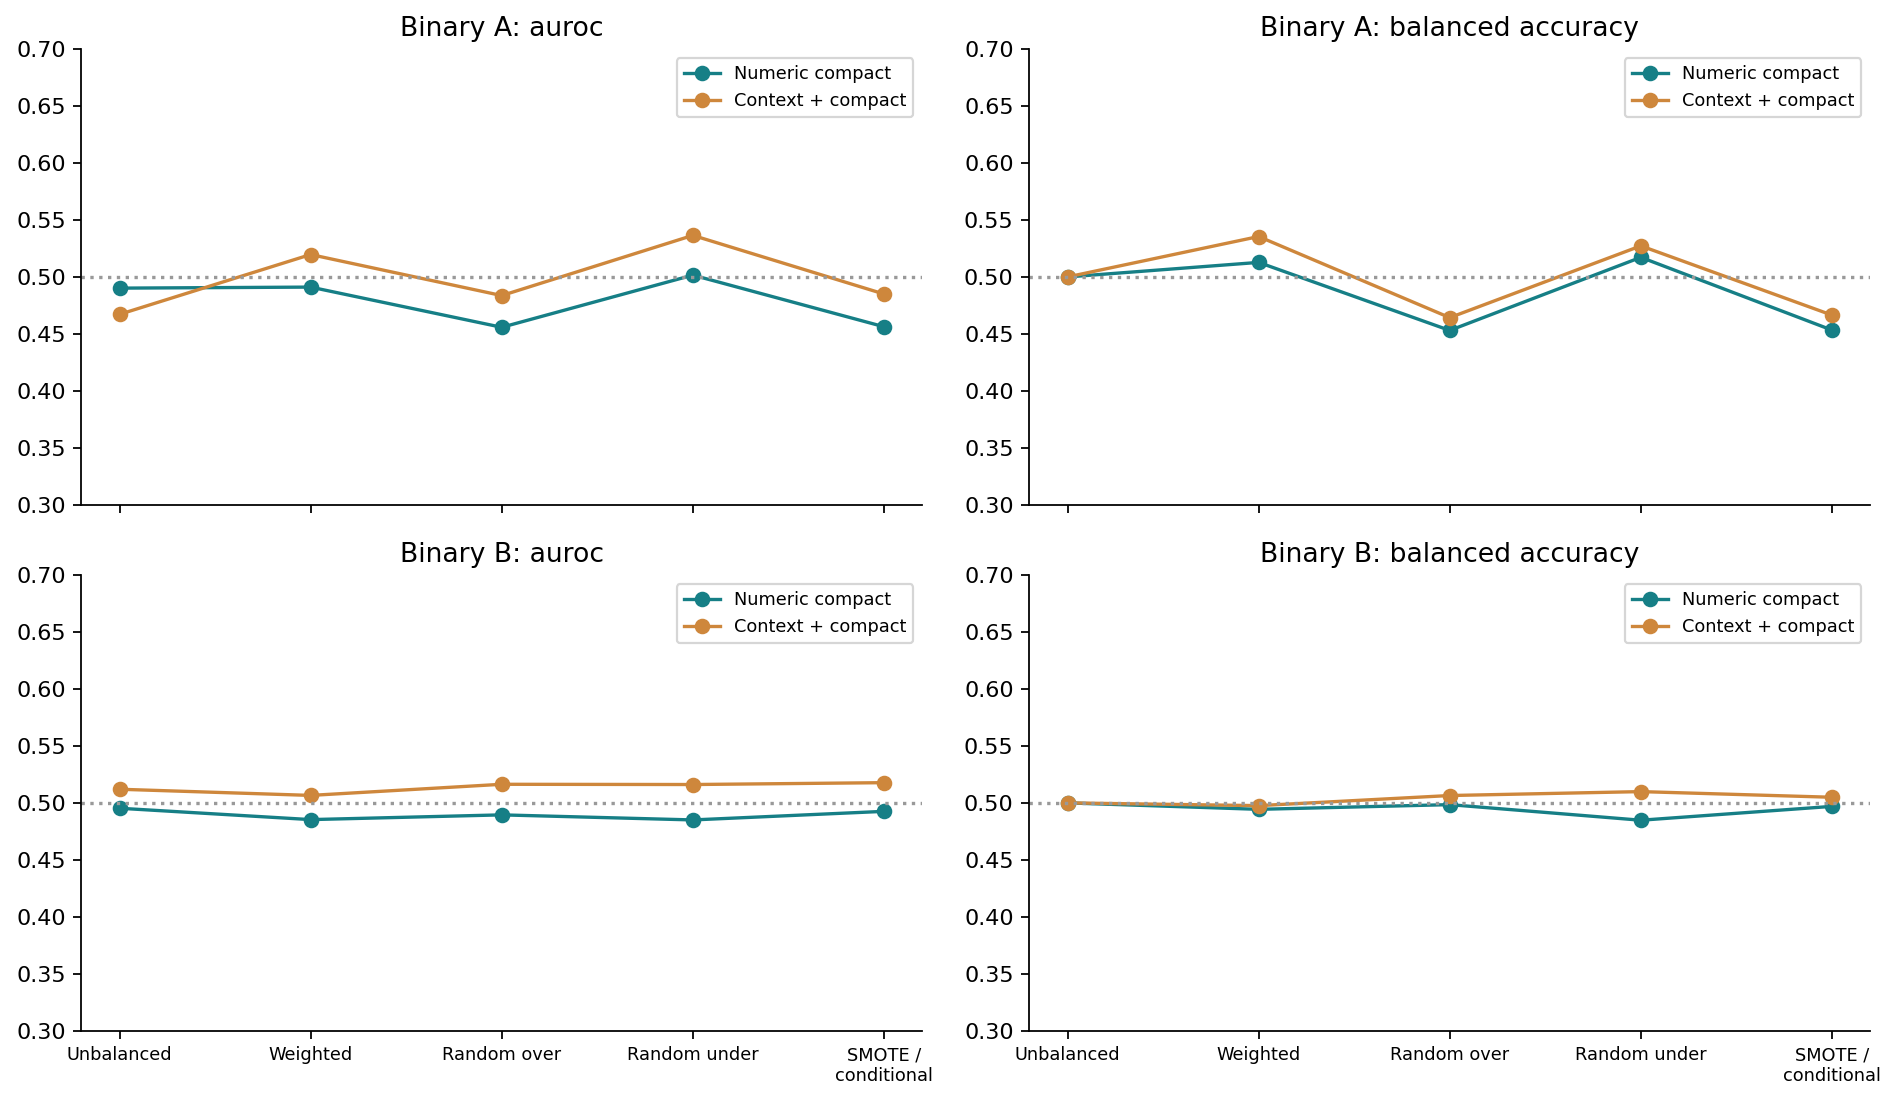

,augmented_rows,cross_category_rows,cross_person_rows,donor_missing_rows,fold,inner_fold,method,model,original_counts,resampled_counts,synthetic_rows,task
0,0,0,0,0,0,0,none,activity120,"[535, 1464]","[535, 1464]",0,A
1,0,0,0,0,0,1,none,activity120,"[529, 1419]","[529, 1419]",0,A
2,0,0,0,0,0,2,none,activity120,"[534, 1415]","[534, 1415]",0,A
3,0,0,0,0,0,outer_refit,none,activity120,"[799, 2149]","[799, 2149]",0,A
4,0,0,0,0,1,0,none,activity120,"[551, 1416]","[551, 1416]",0,A
...,...,...,...,...,...,...,...,...,...,...,...,...
2555,0,0,0,0,3,outer_refit,weighted,context_control_weighted,"[2563, 399]","[2563, 399]",0,B
2556,0,0,0,0,4,0,weighted,context_control_weighted,"[1684, 298]","[1684, 298]",0,B
2557,0,0,0,0,4,1,weighted,context_control_weighted,"[1685, 290]","[1685, 290]",0,B
2558,0,0,0,0,4,2,weighted,context_control_weighted,"[1705, 290]","[1705, 290]",0,B


# Matched context-control amendment

Written after inspecting the completed 600 primary-stage fits, before computing these additional
controls. The original specification and results remain intact. This is a disclosed comparison
correction, not an independently prospectively specified new discovery experiment.

The contextual compact weighted/over/under/conditional models require context-only counterparts
with the same training procedure to isolate the contribution of physiological coordinates. Comparing
them only with unweighted context conflates rebalancing with feature information, even on identical
EMA cohorts. This affects all four rebalanced contextual arms, not just the highest observed model.

Add exactly four context-only specifications (balanced weights, random over, random under, and
conditional donor-context copying), for both targets and all five unchanged outer folds: 40 fits.
Reuse the original 12-candidate logistic grid, grouped inner folds, seed, transforms and threshold rule.
No new feature, sampler, quality rule, model family or threshold objective is introduced.

For conditional augmentation, context comes unchanged from the base donor, exactly as in the
paired contextual physiological model. With zero physiological coordinates there is nothing to
interpolate; these rows are duplicates, not synthetic physiology. Base donors are chosen before
neighbor sampling, so the context rows/labels match the physiological arm. Verify original and
resampled counts, outer/inner membership, and base-donor row multisets for all four comparisons.

Report each contextual compact model versus its matching context control. Preserve the unweighted
context comparisons and label the new contrasts. Do not revise primary conclusions, select an outer
winner, or call the added controls independent confirmation. Save source/configuration hashes in a
separate immutable control-stage bundle and preserve the initial aggregate results privately.


,ap,ap_high,ap_low,ap_valid_draws,auroc,auroc_high,auroc_low,auroc_valid_draws,balanced_accuracy,balanced_accuracy_high,balanced_accuracy_low,balanced_accuracy_valid_draws,cohort,model,reference,task
0,-0.025373,0.006387,-0.057397,2000,-0.056628,0.002742,-0.115889,2000,-0.082039,-0.010820,-0.152284,2000,all,context_compact_conditional,context_control_conditional,A
1,-0.026117,0.005866,-0.058079,2000,-0.057995,0.002108,-0.117286,2000,-0.084272,-0.013472,-0.155603,2000,all,context_compact_over,context_control_over,A
2,-0.003017,0.013356,-0.019739,2000,0.000764,0.026792,-0.025601,2000,-0.003276,0.013963,-0.020565,2000,all,context_compact_under,context_control_under,A
3,-0.006749,0.013187,-0.027141,2000,0.004049,0.044932,-0.039423,2000,0.020127,0.069932,-0.029181,2000,all,context_compact_weighted,context_control_weighted,A
4,-0.017083,0.000630,-0.040075,2000,-0.006550,0.016936,-0.030225,2000,-0.006472,0.018888,-0.032349,2000,all,context_compact_conditional,context_control_conditional,B
5,-0.019182,-0.001113,-0.042120,2000,-0.007970,0.015624,-0.032552,2000,-0.004948,0.022956,-0.031988,2000,all,context_compact_over,context_control_over,B
6,-0.005294,0.014165,-0.029748,2000,0.000143,0.040382,-0.040746,2000,-0.000732,0.028224,-0.031569,2000,all,context_compact_under,context_control_under,B
7,-0.009062,0.001750,-0.019790,2000,-0.025258,0.001425,-0.050795,2000,-0.018028,0.015876,-0.048880,2000,all,context_compact_weighted,context_control_weighted,B


In [5]:
figure("04_rebalance")
table("resampling")
display(Markdown((report/"context_control_amendment.md").read_text()))
table("matched_context_controls")

## Ranking versus decisions and calibration

Inner-fold thresholds change decisions, not AUROC. A prior shift can damage probability calibration. Prior correction is a limited sensitivity.

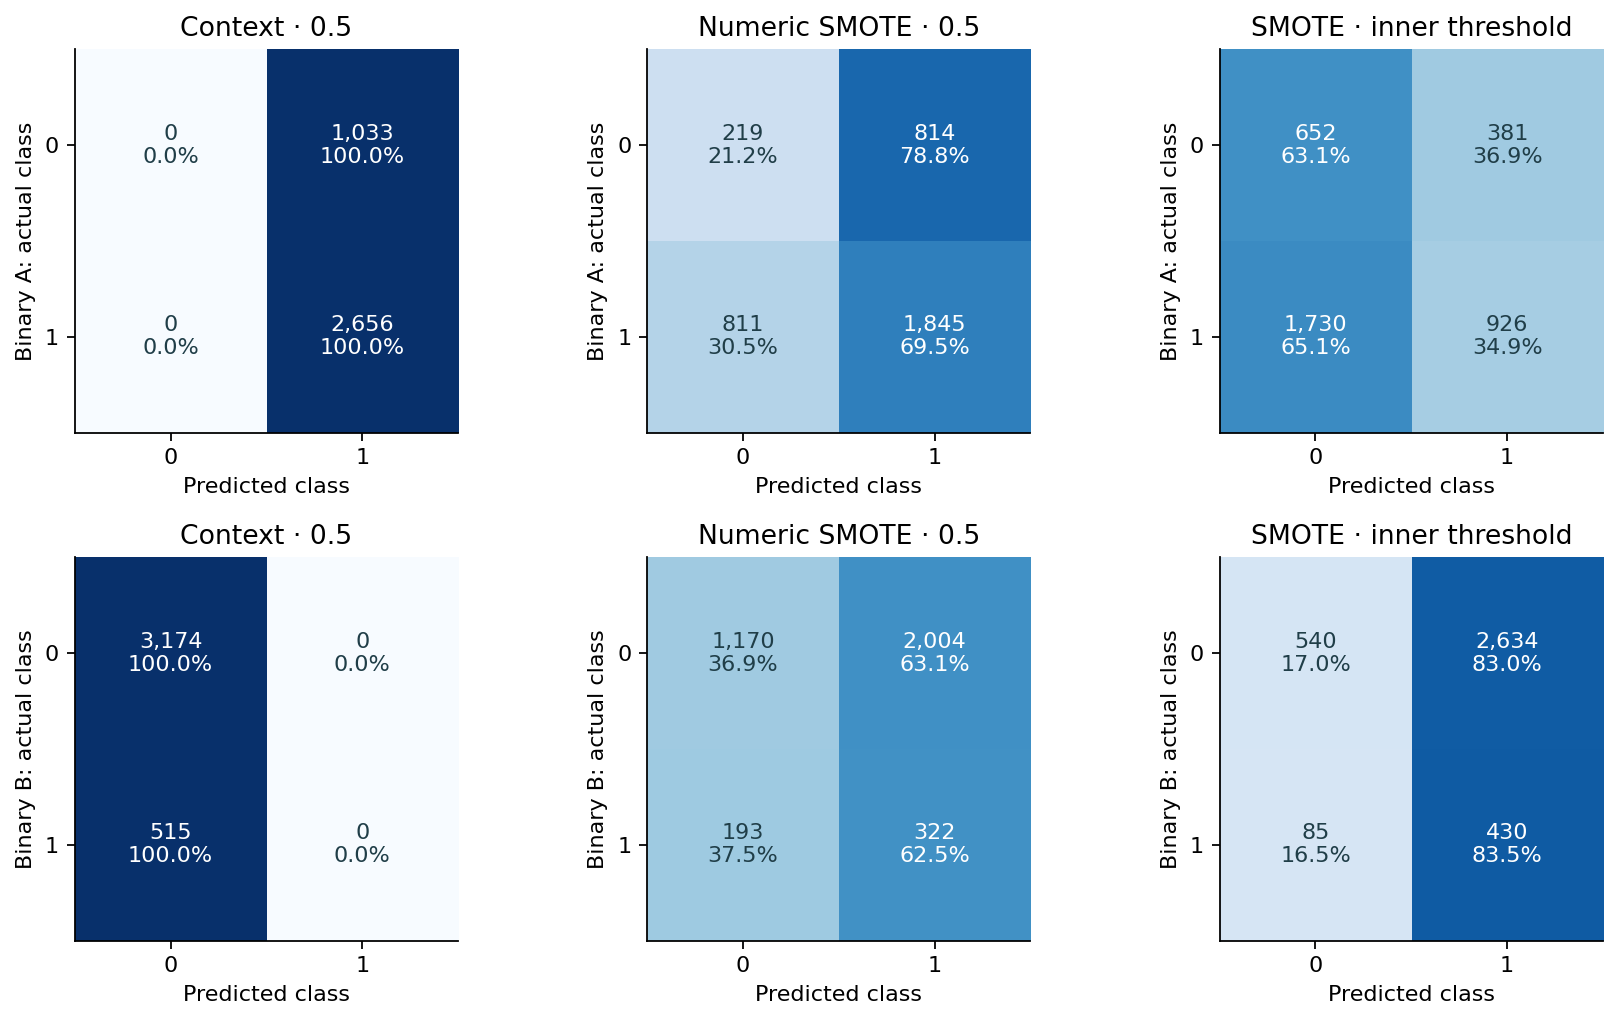

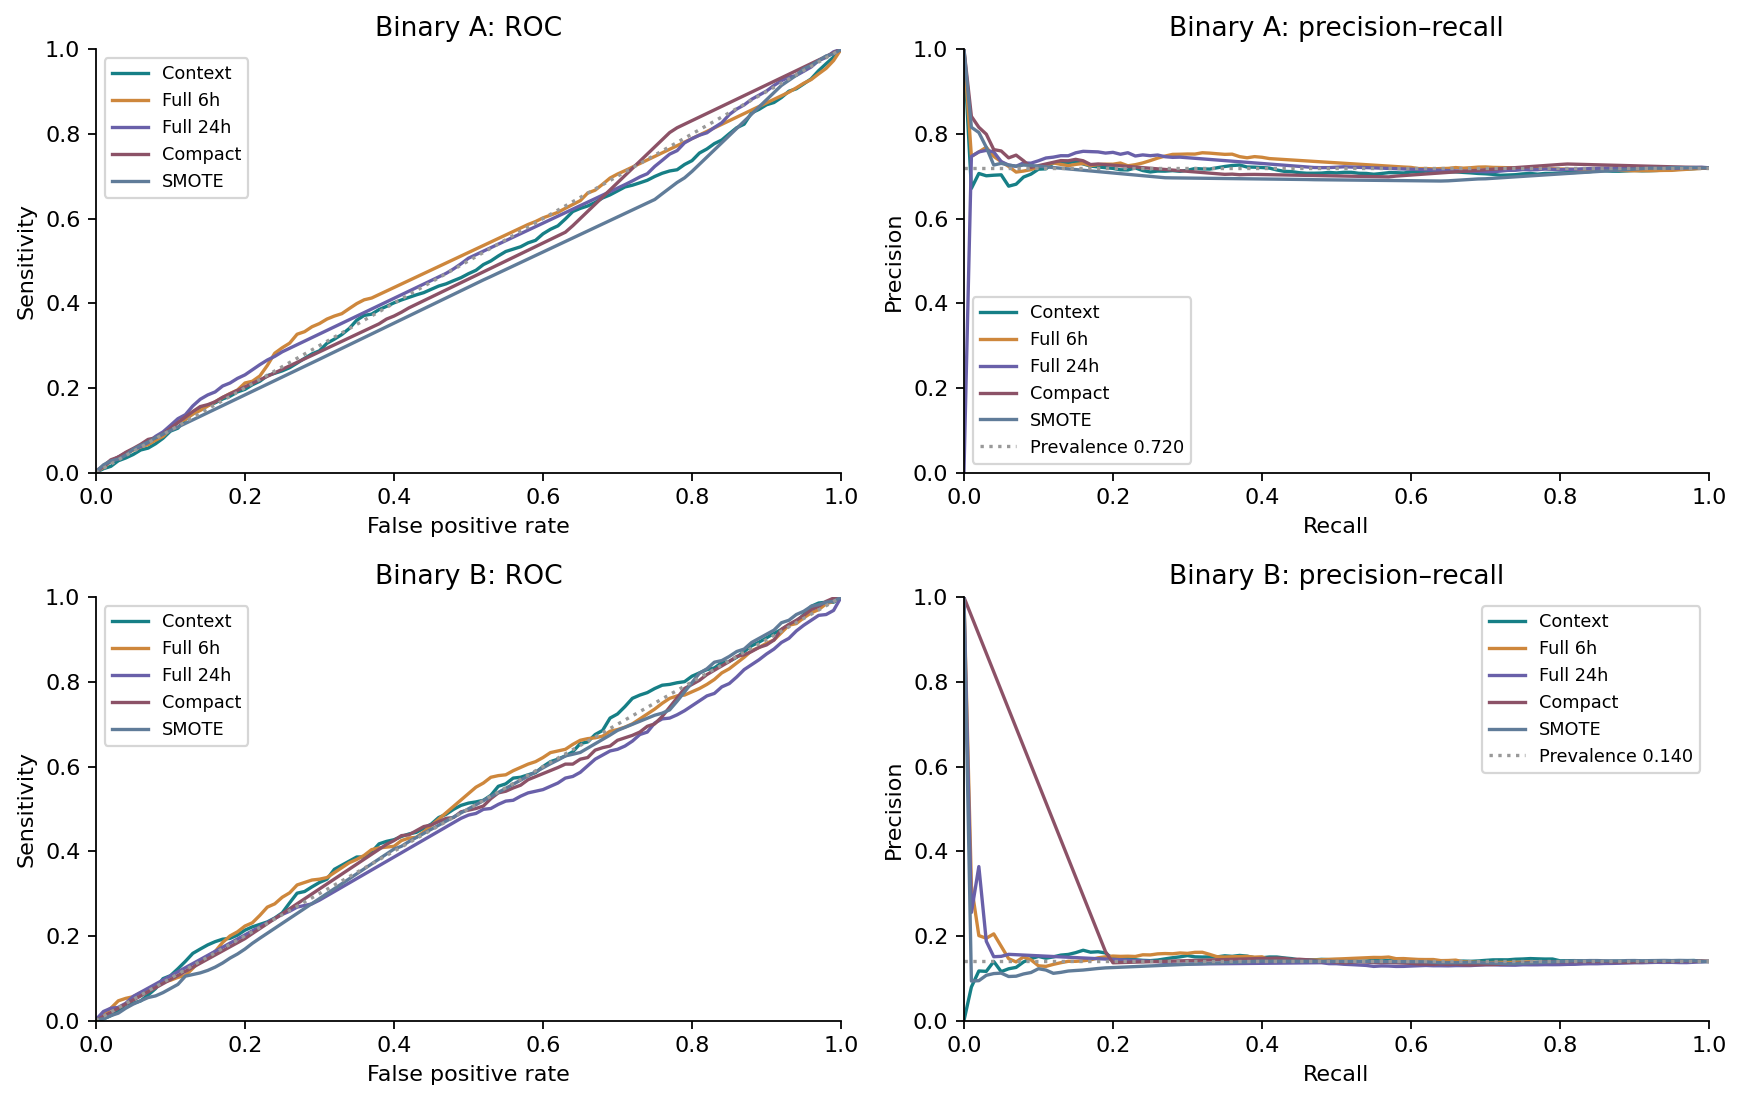

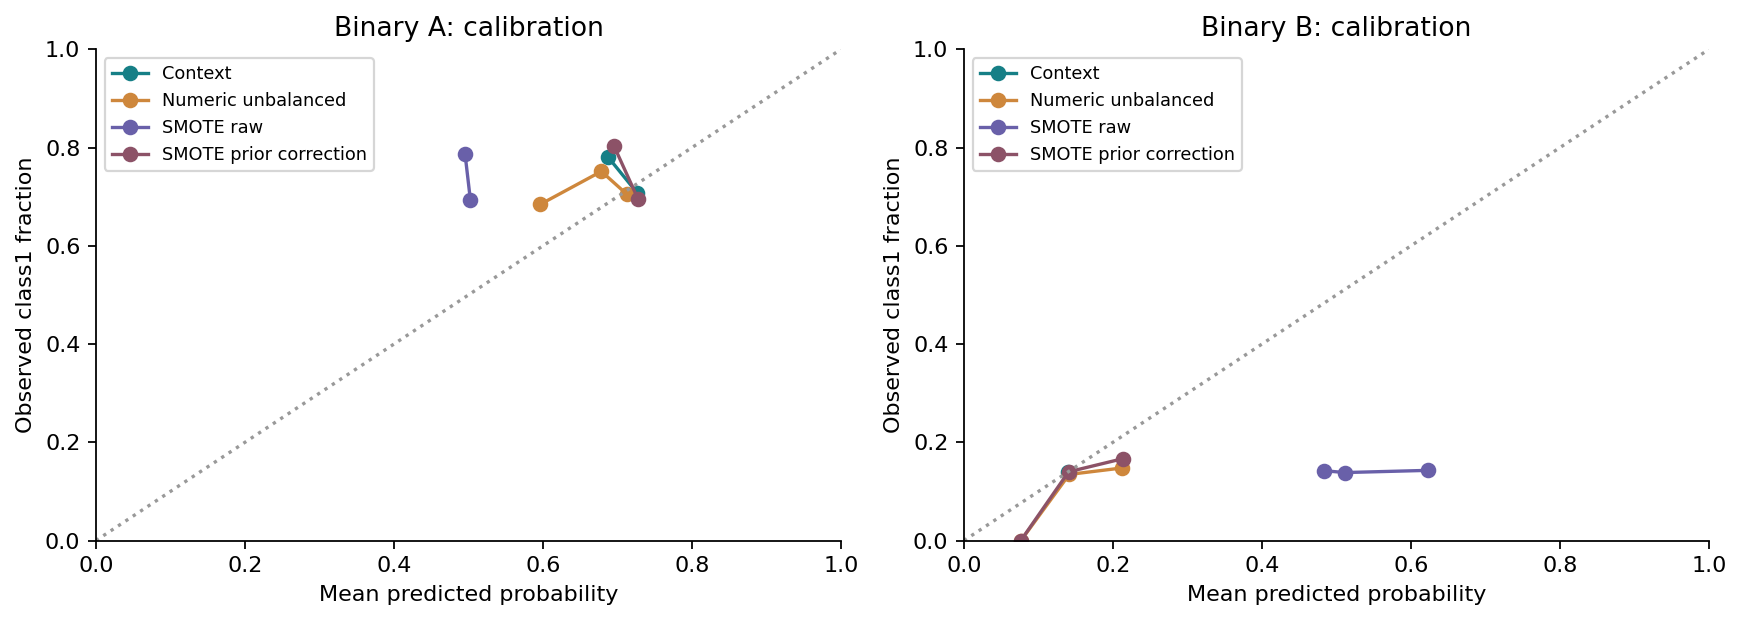

,accuracy,ap,auroc,balanced_accuracy,brier,cohort,f1,fn,fp,mode,...,precision,predicted_positive,prevalence,probability_sd,responses,sensitivity,specificity,task,tn,tp
0,0.715912,0.735398,0.519208,0.498064,0.204456,all,0.834282,18,1030,default,...,0.719193,3668,0.719978,0.065630,3689,0.993223,0.002904,A,3,2638
1,0.539713,0.735398,0.519208,0.514417,0.204456,all,0.641470,1137,561,inner_BA_threshold,...,0.730288,2080,0.719978,0.065630,3689,0.571913,0.456922,A,472,1519
2,0.715912,0.735398,0.519208,0.498064,0.204456,all,0.834282,18,1030,prior_corrected_default,...,0.719193,3668,0.719978,0.065630,3689,0.993223,0.002904,A,3,2638
3,0.719978,0.730607,0.497476,0.500000,0.203361,all,0.837195,0,1033,default,...,0.719978,3689,0.719978,0.042676,3689,1.000000,0.000000,A,0,2656
4,0.495527,0.730607,0.497476,0.471014,0.203361,all,0.600558,1257,604,inner_BA_threshold,...,0.698452,2003,0.719978,0.042676,3689,0.526732,0.415295,A,429,1399
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
427,0.884868,0.115132,0.500000,0.500000,0.115132,supported,0.000000,70,0,inner_BA_threshold,...,0.000000,0,0.115132,0.000000,608,0.000000,1.000000,B,538,0
428,0.884868,0.115132,0.500000,0.500000,0.115132,supported,0.000000,70,0,prior_corrected_default,...,0.000000,0,0.115132,0.000000,608,0.000000,1.000000,B,538,0
429,0.860396,0.142852,0.520430,0.500000,0.120449,all,0.000000,515,0,default,...,0.000000,0,0.139604,0.023692,3689,0.000000,1.000000,B,3174,0
430,0.578477,0.142852,0.520430,0.514291,0.120449,all,0.219769,296,1259,inner_BA_threshold,...,0.148173,1478,0.139604,0.023692,3689,0.425243,0.603340,B,1915,219


In [6]:
figure("05_confusion")
figure("06_curves")
figure("07_calibration")
table("thresholds")

## Physiological information versus recording information

Reading values60,60,60 in one minute and120 in another give mean75 but observed-minute mean90. Empty minutes remain missing.

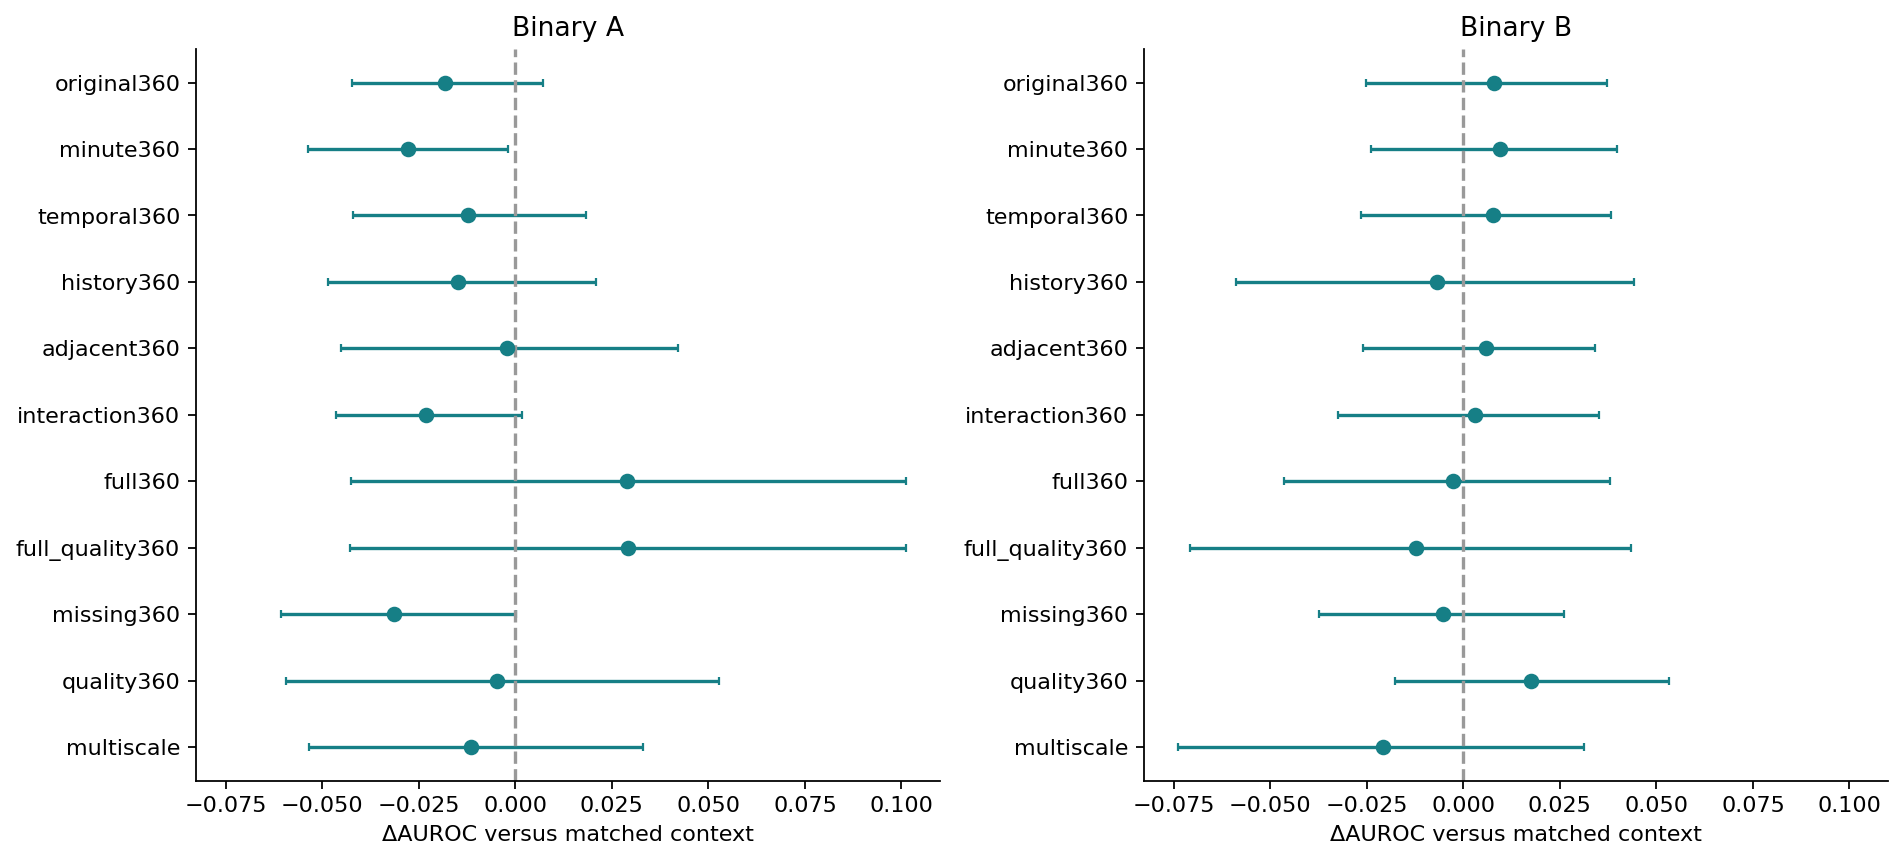

,absolute_difference_median,absolute_difference_observed,absolute_difference_p25,absolute_difference_p75,absolute_difference_p90,correlation,identical_fraction,paired_participants,paired_responses,window
0,0.419380,1652,0.179076,0.759140,1.279176,0.996444,0.001211,119,1652,60
1,0.497648,1828,0.240142,0.847247,1.397816,0.996028,0.000547,120,1828,120
2,0.582191,2643,0.299879,0.989888,1.598931,0.994907,0.001513,123,2643,360
3,0.623620,3065,0.340185,1.024876,1.627095,0.994220,0.001631,123,3065,720
4,0.688190,3431,0.425943,1.064381,1.529401,0.994702,0.000583,123,3431,1440


,all_missing,constant_observed,defined_pairs,features,median_abs_r,pairs_abs_r_over_095,window
0,0,0,1066,47,0.121859,20,60
1,0,0,1066,47,0.100884,17,120
2,0,0,1072,47,0.082582,17,360
3,0,0,1067,47,0.083027,16,720
4,0,0,1074,47,0.076415,18,1440


In [7]:
figure("09_representations")
table("weighting_differences")
table("feature_correlations")

## Coverage, gaps and representation

A 24-hour lookback is not 24 hours of recording. Quality predictors and support-filtered cohorts are explicitly separate.

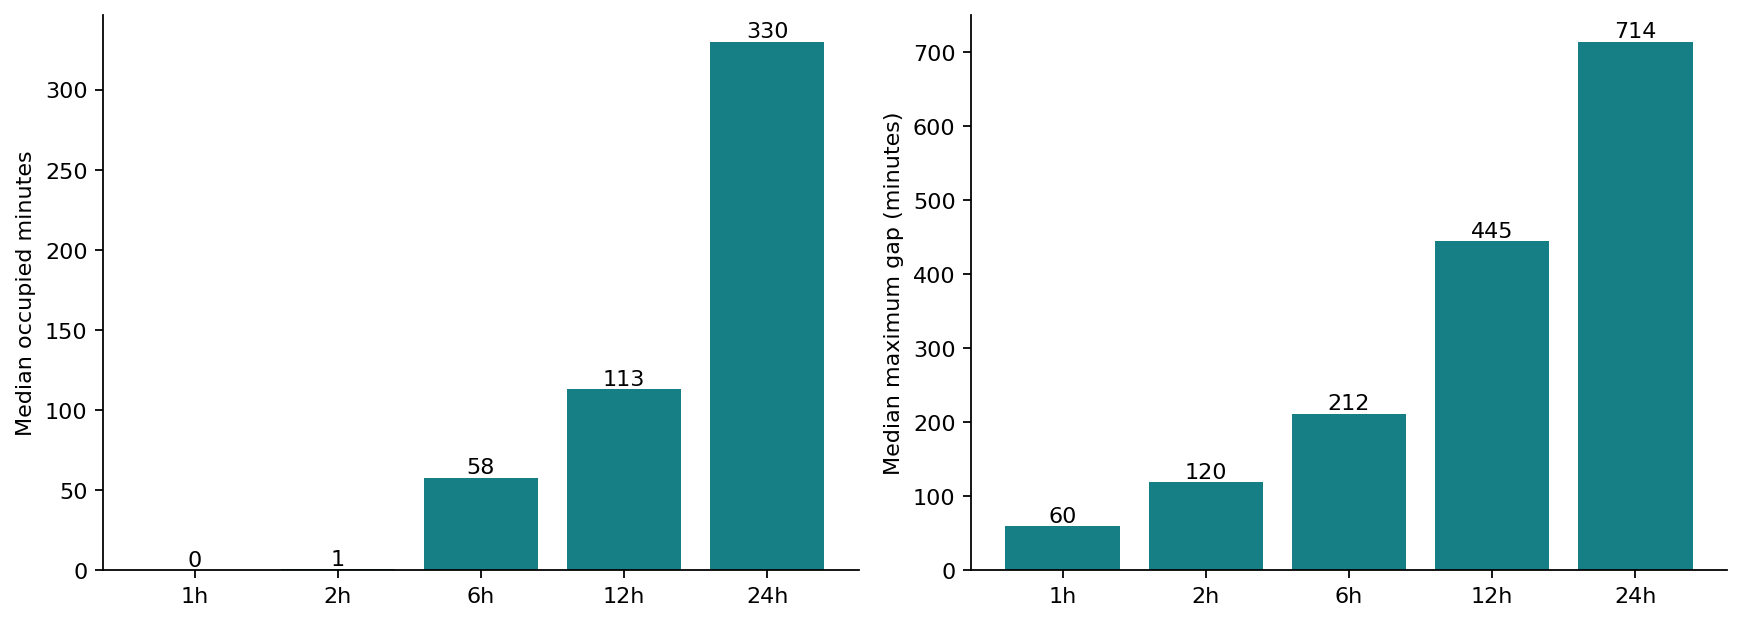

,gain,median,no_gain,observed,p25,p75,p90,reference,responses,window
0,2152,240.0,1537,3689,0.0,4634.0,10626.2,360,3689,720
1,3297,8390.0,392,3689,1544.0,16281.0,24326.4,360,3689,1440


,accuracy,ap,ap_high,ap_low,ap_valid_draws,auroc,auroc_high,auroc_low,auroc_valid_draws,balanced_accuracy,...,positive_support,precision,predicted_positive,probability_sd,responses,sensitivity,specificity,task,tn,tp
0,0.751645,0.751921,0.826510,0.684509,2000,0.503616,0.598732,0.406601,2000,0.5,...,457,0.751645,608,0.015068,608,1.0,0.0,A,0,457
1,0.751645,0.758408,0.831239,0.681804,2000,0.509579,0.596813,0.422097,2000,0.5,...,457,0.751645,608,0.016015,608,1.0,0.0,A,0,457
2,0.751645,0.768438,0.837774,0.692965,2000,0.485567,0.562611,0.410352,2000,0.5,...,457,0.751645,608,0.055211,608,1.0,0.0,A,0,457
3,0.884868,0.101832,0.155021,0.069898,2000,0.460143,0.546008,0.377739,2000,0.5,...,70,0.000000,0,0.008717,608,0.0,1.0,B,538,0
4,0.884868,0.111794,0.175909,0.073545,2000,0.476022,0.547990,0.395128,2000,0.5,...,70,0.000000,0,0.021499,608,0.0,1.0,B,538,0
5,0.884868,0.120434,0.179609,0.076242,2000,0.449071,0.526118,0.368158,2000,0.5,...,70,0.000000,0,0.030904,608,0.0,1.0,B,538,0


In [8]:
figure("08_support")
table("new_readings")
table("restricted_evaluation")

## Recall and diagnostic limits

Morning wake is known from the current response: retrospective-only. Prior prompt logs are unavailable. Full-record context residuals/person means are descriptive only and never predictors.

In [9]:
table("survey_metrics")
table("influence")
table("class_associations")

,accuracy,ap,auroc,balanced_accuracy,brier,f1,fn,fp,model,negative_f1,...,predicted_positive,prevalence,probability_sd,responses,sensitivity,specificity,survey,task,tn,tp
0,0.700644,0.716366,0.487309,0.497266,0.211151,0.823752,6,273,activity120,0.007117,...,925,0.706009,0.063313,932,0.990881,0.003650,Endday,A,1,652
1,0.703176,0.729171,0.515291,0.497243,0.209249,0.825499,12,530,activity120,0.007326,...,1812,0.708653,0.068221,1826,0.990726,0.003759,Midday,A,2,1282
2,0.756176,0.735255,0.486556,0.500000,0.188353,0.861162,0,227,activity120,0.000000,...,931,0.756176,0.054922,931,1.000000,0.000000,Morning,A,0,704
3,0.706009,0.724464,0.506312,0.500000,0.209235,0.827673,0,274,activity1440,0.000000,...,932,0.706009,0.043815,932,1.000000,0.000000,Endday,A,0,658
4,0.708653,0.716868,0.498556,0.500000,0.208082,0.829487,0,532,activity1440,0.000000,...,1826,0.708653,0.041822,1826,1.000000,0.000000,Midday,A,0,1294
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
387,0.883333,0.116667,0.500000,0.500000,0.116667,0.000000,42,0,supported_majority,0.938053,...,0,0.116667,0.000000,360,0.000000,1.000000,Midday,B,318,0
388,1.000000,NaN,NaN,NaN,0.000000,0.000000,0,0,supported_majority,1.000000,...,0,0.000000,0.000000,12,0.000000,1.000000,Morning,B,12,0
389,0.875536,0.154531,0.554635,0.500000,0.108740,0.000000,116,0,temporal360,0.933638,...,0,0.124464,0.019943,932,0.000000,1.000000,Endday,B,816,0
390,0.867470,0.118712,0.467165,0.500000,0.116232,0.000000,242,0,temporal360,0.929032,...,0,0.132530,0.022290,1826,0.000000,1.000000,Midday,B,1584,0


,leave_one_participant_out_max,leave_one_participant_out_min,model,task
0,0.502117,0.478637,compact_none,A
1,0.463995,0.444152,compact_smote,A
2,0.483563,0.472989,context,A
3,0.513184,0.495740,full1440,A
4,0.514361,0.499558,full360,A
5,0.485580,0.475007,full720,A
6,0.512225,0.482724,compact_none,B
7,0.501503,0.480317,compact_smote,B
8,0.521467,0.509198,context,B
9,0.494271,0.467487,full1440,B


,class0,class1,class1_minus_class0,feature,leave_one_person_out_difference_max,leave_one_person_out_difference_min,participants,representation,responses,standardized_difference,task,within_person_contrast_participants,within_person_equal_weight_difference
0,771,1908,0.301022,hr__mean__360m,0.525752,-0.016342,123,observed,2679,0.028021,A,83,-1.834620
1,771,1908,0.396070,hr__mean__360m,0.633989,0.086397,123,context_residual,2679,0.037256,A,83,-1.671404
2,771,1908,0.109327,hr__sd__360m,0.182421,-0.072502,123,observed,2679,0.031678,A,83,-0.514457
3,771,1908,0.109798,hr__sd__360m,0.187784,-0.072161,123,context_residual,2679,0.031999,A,83,-0.499178
4,771,1911,1.201830,hr__latest__360m,1.420509,0.886540,123,observed,2682,0.082433,A,83,-1.218726
5,771,1911,1.248490,hr__latest__360m,1.462784,0.939280,123,context_residual,2682,0.085865,A,83,-1.092301
6,744,1864,0.041041,hr__slope__360m,0.074526,0.002212,123,observed,2608,0.021625,A,81,0.025494
7,744,1864,0.034464,hr__slope__360m,0.069359,-0.002796,123,context_residual,2608,0.018231,A,81,0.020168
8,674,1657,30.164372,steps__supported_rate__360m,30.829839,7.260673,123,observed,2331,0.038308,A,80,3.292190
9,674,1657,30.708855,steps__supported_rate__360m,31.477522,7.781349,123,context_residual,2331,0.039018,A,80,3.602916


## Findings and verification

Interpret matched differences and conditional intervals, not the largest point AUROC or improved F1 alone.

In [10]:
display(Markdown((report/"summary_for_will.md").read_text()))
table("verification")
if (report/"verification.md").exists(): display(Markdown((report/"verification.md").read_text()))

# Binary stress improvement — summary for Will

**The primary comparisons do not establish a clear AUROC improvement.**

All main comparisons retain identical 3,689 responses from 125 development participants. All 3,706 EMAs remain accounted for. Previous six-hour full AUROC was 0.508 (A) and 0.510 (B); exact refit replays are verified.

**1. Did 12 or 24 hours outperform six hours?** Binary A: 12h ΔAUROC -0.029 (95% interval -0.093 to +0.033); 24h ΔAUROC -0.004 (95% interval -0.078 to +0.069). Binary B: 12h ΔAUROC -0.001 (95% interval -0.054 to +0.052); 24h ΔAUROC -0.034 (95% interval -0.089 to +0.024).

**2. Did SMOTE improve ranking or just detection?** Binary A: ΔAUROC -0.034 (95% interval -0.140 to +0.073); SMOTE AUROC 0.456, sensitivity 69.5%, precision 69.4%. Binary B: ΔAUROC -0.003 (95% interval -0.062 to +0.053); SMOTE AUROC 0.493, sensitivity 62.5%, precision 13.8%. These are numeric-only compact comparisons; contextual conditional SMOTE is a separate procedure. For Binary B, raw SMOTE Brier score worsens to 0.251 from 0.122; lower is better. Prior correction largely restores prevalence calibration but does not establish discrimination.

**3. Which cutoff discriminates better?** Binary A: full 24h AUROC 0.504 (0.456–0.552), positive prevalence 72.0%. Binary B: full 24h AUROC 0.476 (0.417–0.542), positive prevalence 14.0%. The tasks differ; raw AP does not rank cutoffs fairly across prevalence.

**4. Did representation changes help?** Binary A: observed-minute HR4 versus reading HR4 ΔAUROC -0.010 (95% interval -0.032 to +0.012). Binary B: observed-minute HR4 versus reading HR4 ΔAUROC +0.002 (95% interval -0.004 to +0.008). History, disjoint contrasts, observed-block variation and supported activity strata have separate matched results below. No feature definition is chosen using outer performance.

**5. What is the largest logistic AUROC?** Binary A: context only with random oversampling (added matched control), AUROC 0.542 (0.510–0.572); fold range 0.500–0.512. Versus matching context: ΔAUROC +0.063 (95% interval -0.006 to +0.131). Binary B: context + original four HR summaries over 12 hours, AUROC 0.542 (0.504–0.578); fold range 0.504–0.618. Versus matching context: ΔAUROC +0.029 (95% interval -0.008 to +0.062). A secondary Binary B HR4 comparison, 12h versus 6h, has ΔAUROC +0.0209 (+0.0004 to +0.0427). This narrow positive conditional interval is one of many exploratory comparisons; its increment over context remains uncertain. These are post-inspection point maxima on the main all-valid cohort, not independently validated winners; quality-only controls must not be relabeled physiology.

**6. Does physiology beat context?** Binary A: full 24h versus context ΔAUROC +0.025 (95% interval -0.033 to +0.082). Binary B: full 24h versus context ΔAUROC -0.037 (95% interval -0.083 to +0.007). The full model includes missingness indicators; no-flags and missingness-only controls distinguish value and recording information. A disclosed post-result amendment added 40 fits with matched context-only rebalancing. All eight physiological increments have intervals including zero. For A undersampling: ΔAUROC +0.001 (95% interval -0.026 to +0.027). Its apparent advantage over unweighted context is therefore not evidence of added physiology. The largest A AUROC is now a context-only control; it must not be relabeled physiological signal.

**7. Which features consistently contributed?** In the secondary Binary B 12-hour HR4 model, HR SD was negative and latest HR/slope positive in all five fits. Missing-HR-mean and missing-HR-SD flags were also positive in all five fits. The leading Binary A undersampling model did not consistently retain most physiological coefficients. Correlated features can substitute; coefficient magnitudes across scaled readings and unscaled indicators are not directly comparable. These are training associations, not validated contributions. A matched 12-hour no-flags/missingness-only confirmation remains a future experiment, not an outcome-driven expansion here.

**8. What remains blocked?** Across 15 prespecified descriptive feature checks, median absolute context-residualized class differences were small: 0.037 SD (A) and 0.063 SD (B), on feature-specific observed cohorts. Six-hour full features contained 17 pairs with |r|>0.95, but none were wholly constant among observed values. Median occupied minutes were 58/360, 113/720 and 330/1440. The stricter support cohort retained 608 responses/87 people; its matched full-versus-context intervals still included zero. Retrospective wake alignment likewise did not establish an improvement. These checks do not identify one causal explanation: acquisition/receipt timing, batching, quality, counter semantics and prior-prompt logs remain unresolved, and repeated development exploration limits inference.

**9. What should we discuss with Will?** Present all paired intervals, class-specific errors, donor plausibility and calibration costs alongside AUROC. Request collection/export clock code, prompt logs and sensor-quality metadata. Keep any apparent improvement as a hypothesis for a separately specified confirmation; do not expand searches or unseal the final test automatically.

The full audit, exact train/validation and resampled class counts, fold stability, Brier scores, threshold sensitivities, support restrictions and retrospective Morning comparisons are in index.html and the versioned JSON tables. Sampling intervals and activity semantics remain provisional. No clinical or causal interpretation is warranted.

See verification.md for test/replay results. No commit, push, provider message or final-test evaluation.


,augmentation_donors_checked,candidate_evaluations,extra_source_participants,extra_source_traces,failed_jobs,final_test_evaluated,independent_refits,inner_participant_checks,matched_context_control_checks,nonconverged_candidates,original_checkpoint_reproductions,preserved_files,preserved_manifests,primary_prediction_rows_preserved,raw_metadata_checks,training_replays,validation_replays
0,419760,5290,9,36,[],False,8,1920,40,0,180,785,2019,401654,7870,640,640


# Notebook 16 verification

Version `911ce0ce6a7b6943` uses the unchanged supported-feature bundle and frozen development folds.
All 3,706 responses remain accounted for; 3,689 valid-score/context responses form the main cohort.
The final-test participants were not evaluated. No raw sensor extraction or scientific threshold
correction was needed; original artifacts remain unchanged.

| Check | Executed result |
| --- | --- |
| Full test suite | 213 passed; 13 dependency warnings |
| Ruff | Passed |
| Completed outer fits | 640 (600 primary + 40 added context controls), no failed/nonconverged selected fits |
| Candidate evaluations in this checkpoint | 5,290 × three inner folds (15,870 fits); includes 180 reused decisions and 30 fixed negative controls |
| Nonconverged candidates | 0 |
| Exact Notebook 15 prediction reproductions | 180 training/validation model pairs |
| Saved validation/training replays | 640 each, tolerance 1e−12 |
| Independent fresh selected-configuration refits | 8 |
| Inner participant separation checks | 1,920 |
| Resampling lineage records checked | 419,760, all donors inside the corresponding training split |
| Original analysis preserved | All 401,654 original prediction views and every original metric/paired contrast unchanged |
| Matched context-control checks | 40; identical outer/inner memberships, class counts and base-donor sequences |
| Target and independent clock checks | 3,706 each |
| Independent saved window-boundary checks | 74,120 |
| Initial source reading traces | 45 windows from nine EMA keys, one participant source |
| Broader source verification | 36 windows from nine distinct development participants; reading and observed-minute means independently replayed |
| Prior files/private manifests preserved | 785 / 2,019 |
| Raw/reference metadata integrity | 7,870 size/mtime checks; no raw contents reread |

New tests also verify that the four matched context resampling procedures preserve labels and donor-context coordinates exactly.

New tests validate numeric convex interpolation, donor provenance, balanced counts, same-person/
same-category conditional sampling, preservation of cyclic context, training-only compact selection,
threshold choice, analytic prior correction, independent threshold-metric arithmetic, and a held-out synthetic participant positive control.
Existing tests cover offset conversion, precision buffers, long-window overflow, counter resets,
left-inclusive/right-exclusive boundaries, missingness, conflicts, rejected adjacency and feature exclusions.

The source audit uses independently parsed Python datetimes, not the vectorized window generator.
The broader trace uses boolean timestamp masks rather than trusting stored slice indices. No real
participant rows or survey clocks are included in the public notebook/report. Conditional SMOTE donor checks confirm participant
and category equality; numeric-only SMOTE explicitly records cross-person/category mixing and
imputed-donor use. Bounds checks establish arithmetic consistency, not physiological validity.

Thresholds use selected-configuration inner OOF predictions only. Reusing inner predictions for
model and threshold selection can overfit training decisions; outer outcomes never choose either.
Analytic prior correction uses training prevalences only. It is not fitted calibration and can alter
pooled ranking through fold-specific transformations despite preserving within-fold ranks.

All matched differences require identical EMA keys and labels. The 2,000-draw participant bootstrap
conditions on saved OOF predictions; it excludes retuning uncertainty and multiplicity correction.
Three training-label permutation runs are computational controls, not repeated-measures permutation
significance tests. The largest observed model AUROC is descriptive after repeated exploration.

Notebook execution, browser inspection and the final privacy scan are recorded in `completion.json`
when complete. The notebook reads aggregate results only. Prior validators and seals are unchanged;
the checkpoint-local validator permits only the reviewed new aggregate notebook outputs.

Individual accounting, memberships, augmentation donors, estimators and predictions are ignored/private.
No final-test evaluation, commit, push or provider message was performed.
